# Stacked Maps

The following notebook provides a walkthrough on how to both use unspotable in jupyter and also create new stellar surface maps from the original unspotable basis set.

**NOTE:** to run this code, quad-limb-70i-units must already exist in the eridani-outputs folder.

## Library and Data Setup

### Core Imports

In [1]:
#General imports
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from cmcrameri import cm
import faulthandler
faulthandler.enable()

# Directory structure - this is required for running jupyter in a folder
from pathlib import Path
maindir = str(Path(os.getcwd()).parent)
libdir  = os.path.join(maindir, 'lib')
if not libdir in sys.path:
    sys.path.append(maindir)
    sys.path.append(libdir)

# lib imports
from lib import eigen
from lib import utils
from lib import fitclass as fc
from lib.spotable import spotable as se

# import starry2 and set basic configuration
import starry2 as starry
starry.config.quiet = True
starry.config.lazy = True
sys.setrecursionlimit(10000) # starry seems to have a lot of recursion

### Importing each .py file

In [2]:
import create_eigens
import create_emaps
import create_rv
import create_real_null

### Reading Config File

In [3]:
fit = fc.Fit()
fit.read_config("../eridani.cfg")

cfg = fit.cfg

lmax = cfg.sim.lmax
udeg = cfg.star.udeg

# setting up units if present in cfg
if fit.cfg.star.units:
    scaler = 5.670374419e-8 * fit.cfg.star.teff**4
    power = int(np.floor(np.log10(scaler)))
    if power > 6:
        units = f"x10$^{power}$ W m$^{{-2}}$"
    else:
        units = f"W m$^{{-2}}$"
else:
    scaler = 1
    units = None

### Python magic commands for better notebook displays

In [4]:
%matplotlib inline

### Reading in data from quad-limb-70i-units

In [5]:
scaled_eigeny = np.loadtxt("../eridani-outputs/quad-limb-70i-units/stored-scaled-null-eigens/scaled-null-eigeny.txt")

scaled_amps = np.loadtxt("../eridani-outputs/quad-limb-70i-units/stored-scaled-null-eigens/scaled-null-amps.txt")

In [6]:
print(f"Shape: {scaled_eigeny.shape} - {scaled_eigeny.shape[0]} maps with {scaled_eigeny.shape[1]} coefficients")
print(f"Shape: {scaled_amps.shape} - {scaled_amps.shape[0]} maps with {scaled_amps.shape[1]} coefficients (limb ratio & amp)")

Shape: (25, 36) - 25 maps with 36 coefficients
Shape: (25, 2) - 25 maps with 2 coefficients (limb ratio & amp)


## Creating a Star

Let's make a star and modify it a bit

In [7]:
# call initstar using parameters from config file - make sure include_rv = True!
star = utils.initstar(fit, lmax, udeg=udeg, include_rv=True)

To look at the star's flux, you can call it from starry directly:

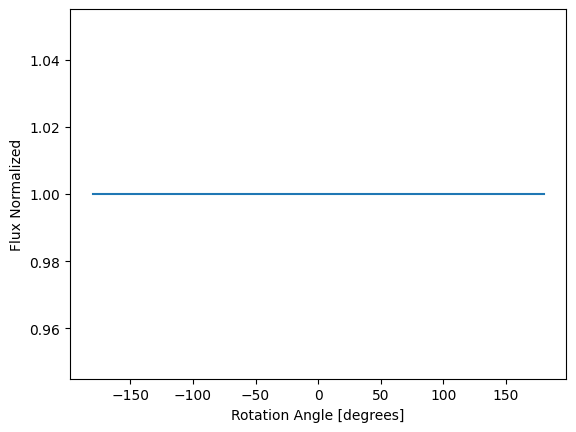

In [8]:
#Let's take a look at the star's flux
theta = np.linspace(-180,180,361)

flux = star.map.flux(theta=theta).eval()

plt.plot(theta,flux)
plt.xlabel("Rotation Angle [degrees]")
plt.ylabel("Flux Normalized")
plt.show()


Or you can call one of the unspotable function!

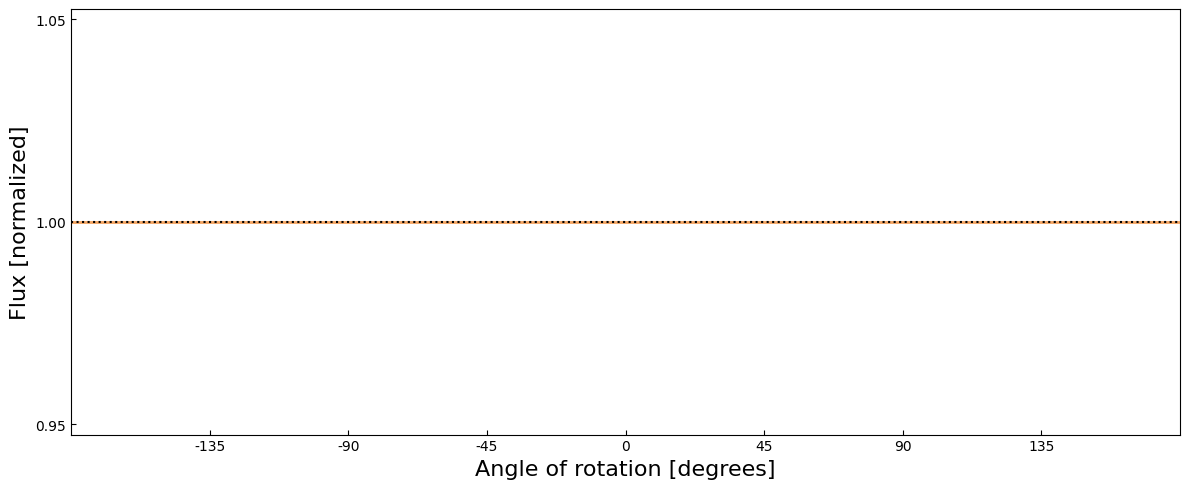

In [9]:
# this has some extra functionality you can play with.  If you are curious see create_rv.py!
create_rv.flux_rv_line(star,theta = theta, flux_only=True)

And we can look at the RV

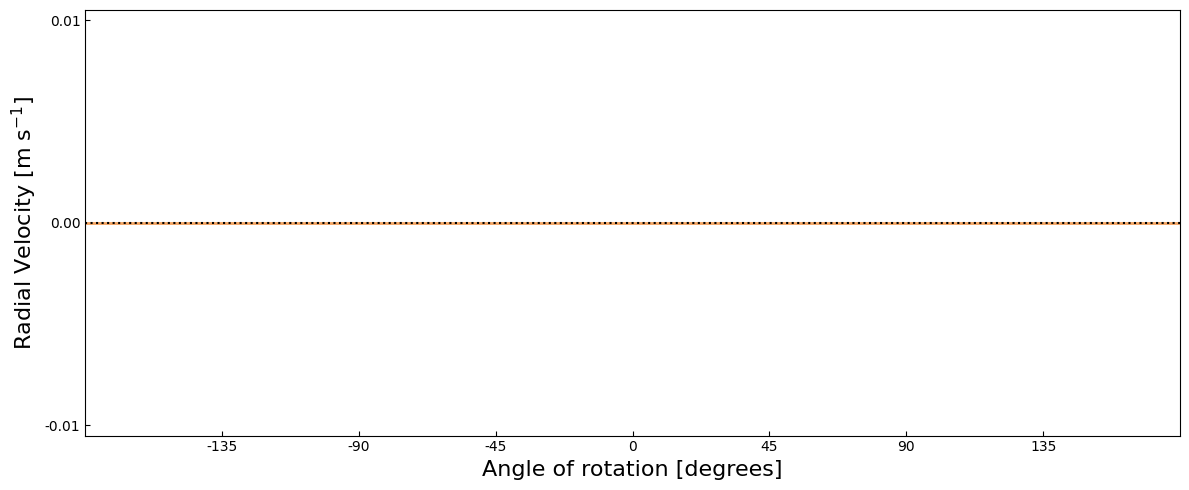

In [10]:
create_rv.flux_rv_line(star,theta = theta, rv_only=True)

Okay, now we can set the star to have some coefficients from our eigenamps

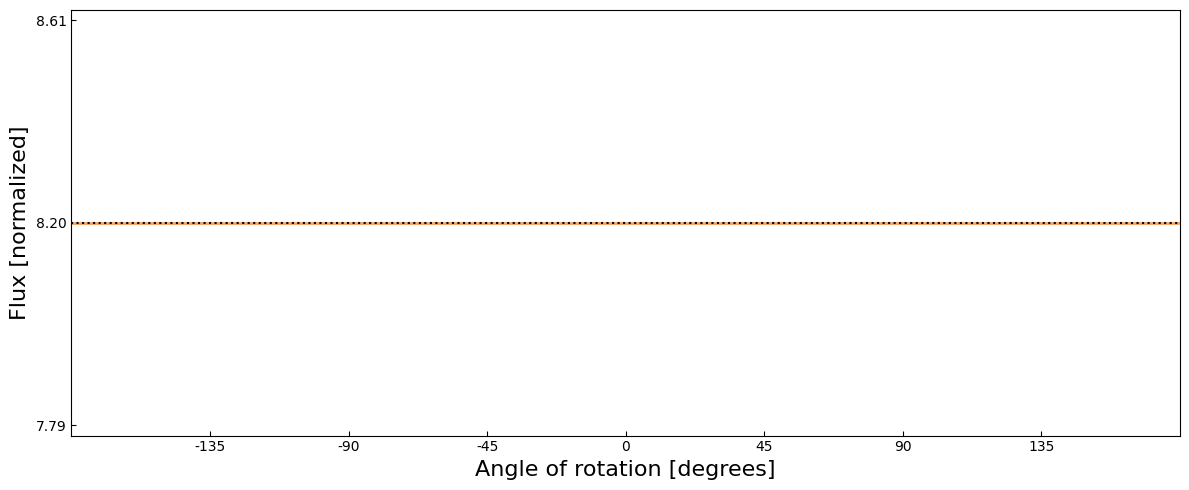

In [11]:
star.map[:,:] = scaled_eigeny[16]

create_rv.flux_rv_line(star,theta = theta, flux_only=True)

As expected for a null space map, the light curve is still zero.  But let's look at the RV

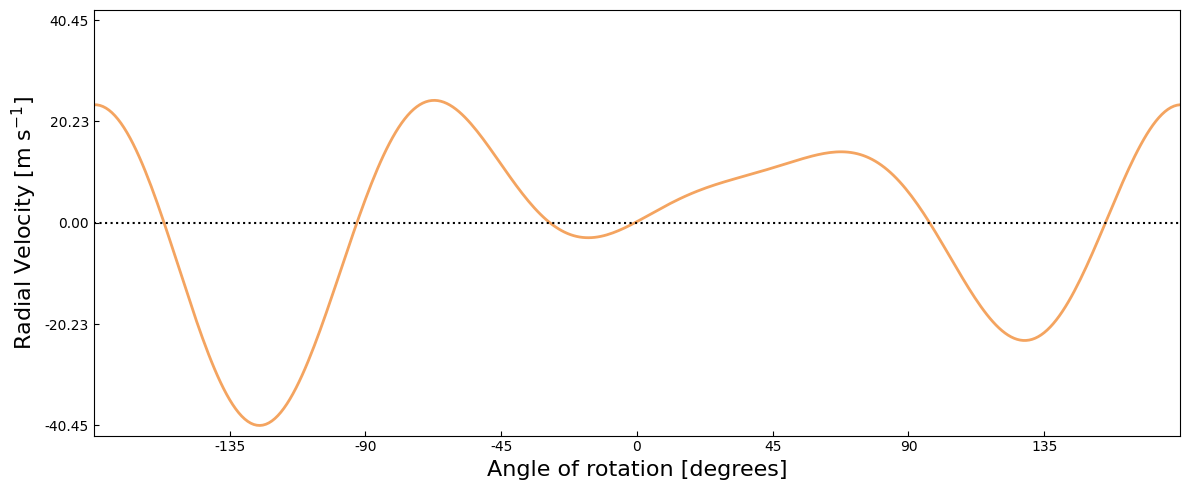

In [12]:
create_rv.flux_rv_line(star,theta = theta, rv_only=True)

And now we have some RV!  If we want to get really fancy we can animate it:

In [13]:
create_rv.map_animations(star, html5_video=True, dpi=100, interval=50)

You'll notice that the flux is set to 7 which is pretty arbitrary.  Let's apply some units to this map

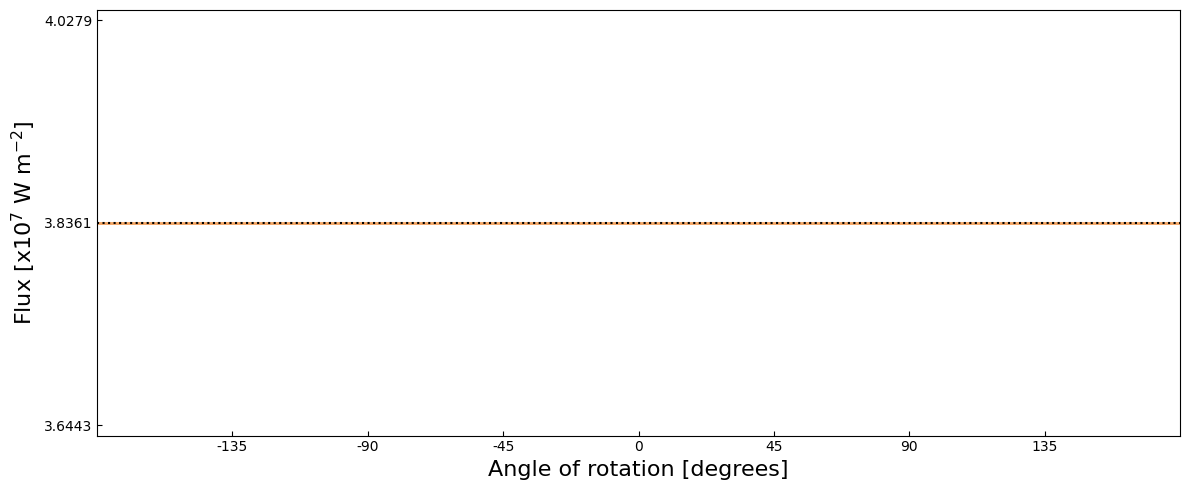

In [14]:
#Here we scale the map to have the expected surface flux values in W m^-2
ratio, amp = scaled_amps[16]

star.map.amp = amp

create_rv.flux_rv_line(star,theta = theta, flux_only=True, units=units)

create_rv.map_animations(star, html5_video=True, dpi=100, interval=50, units=units)

## Stacking two maps on one star

It is quite simply to create a map that contains multiple null space patterns in this code.  Let's make a star to do this with:

In [15]:
stacked_star = utils.initstar(fit, lmax, udeg=udeg, include_rv=True)

As before, we can set it to have null map at index 16 but also add null map at index 3.

Let's make individuals for each of these too to compare!

In [16]:
stacked_star.map[:,:] = scaled_eigeny[16]

stacked_star.map[:,:] += scaled_eigeny[3]

In [17]:
star16 = utils.initstar(fit, lmax, udeg=udeg, include_rv=True)

star16.map[:,:] = scaled_eigeny[16]

star3 = utils.initstar(fit, lmax, udeg=udeg, include_rv=True)

star3.map[:,:] = scaled_eigeny[3]

Time to compare some lightcurves and RVs

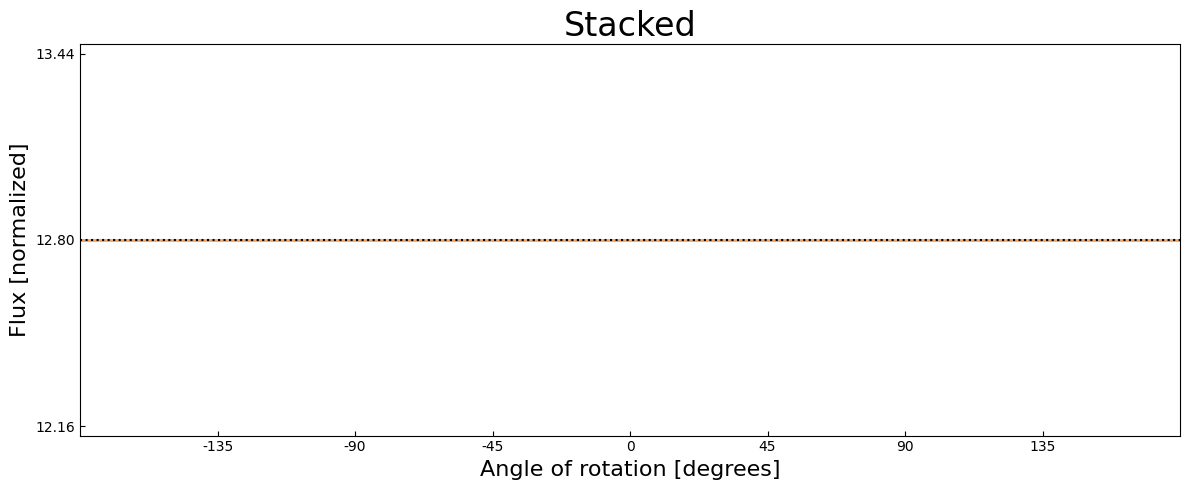

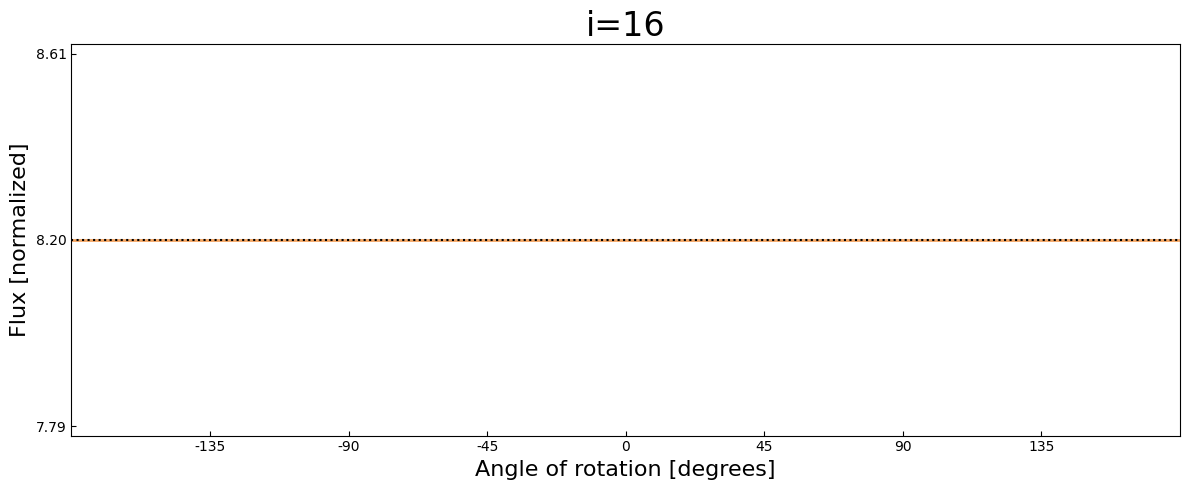

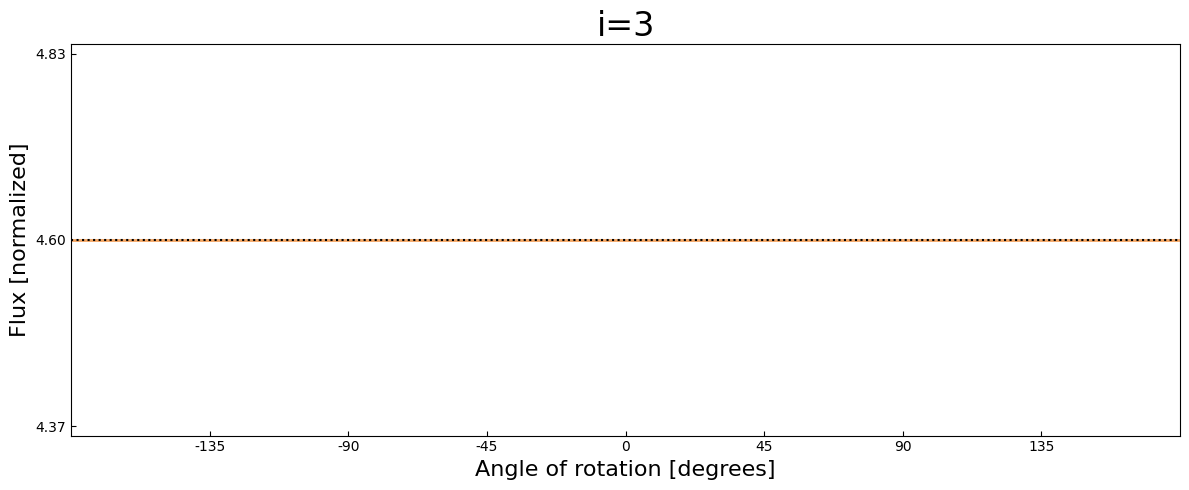

In [18]:
create_rv.flux_rv_line(stacked_star,theta = theta, flux_only=True,title="Stacked")
create_rv.flux_rv_line(star16,theta = theta, flux_only=True,title="i=16")
create_rv.flux_rv_line(star3,theta = theta, flux_only=True,title="i=3")

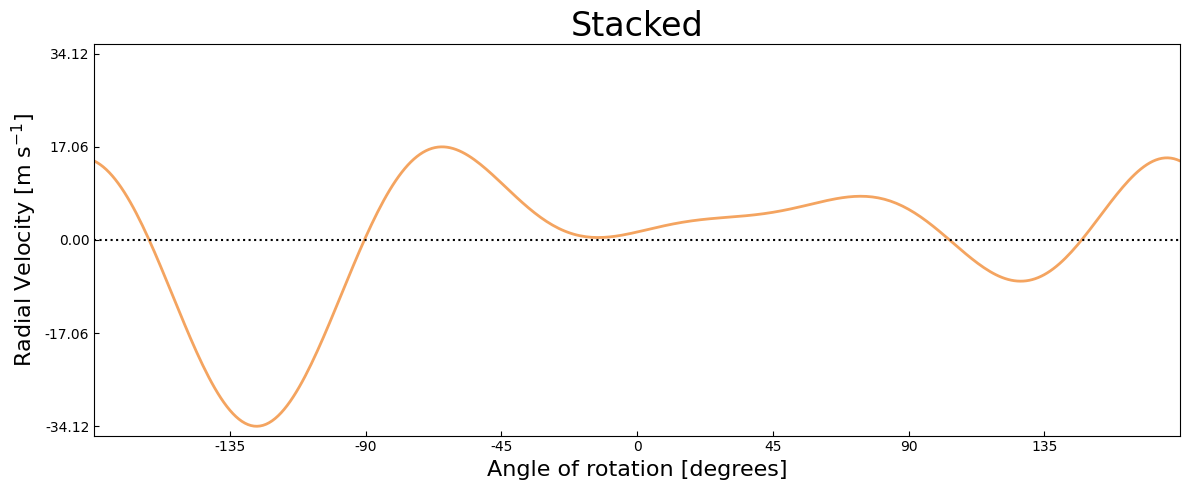

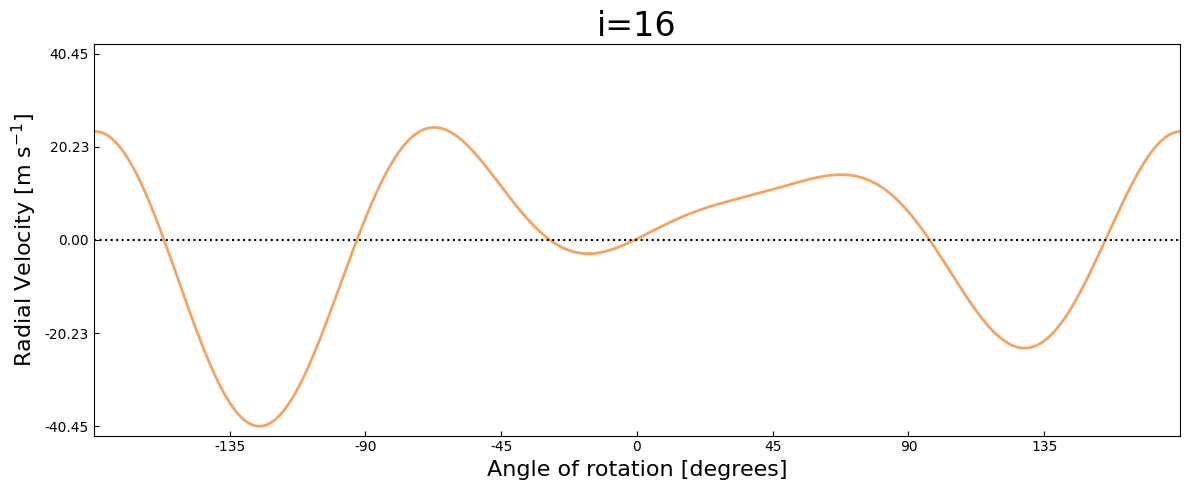

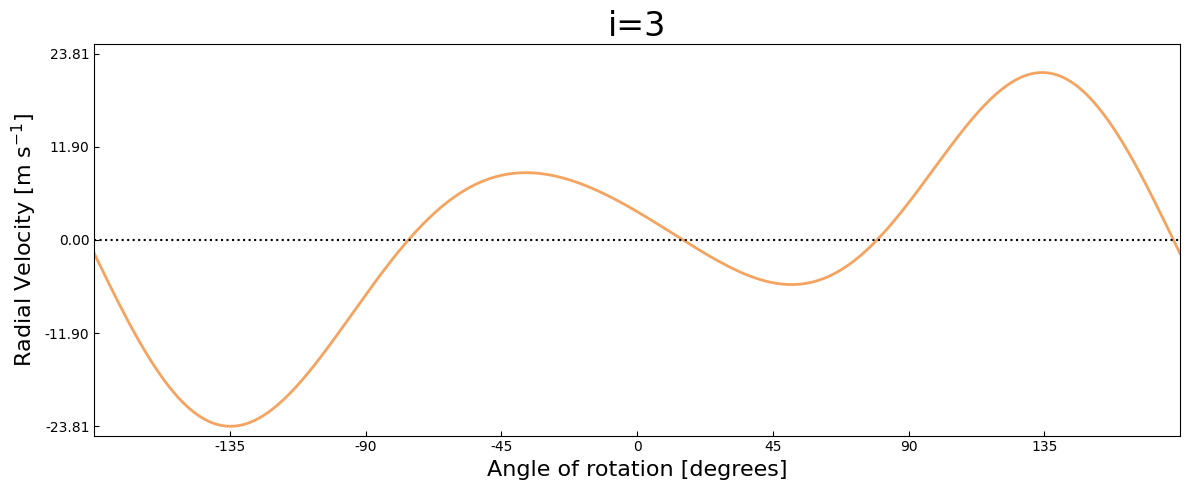

In [19]:
create_rv.flux_rv_line(stacked_star,theta = theta, rv_only=True,title="Stacked")
create_rv.flux_rv_line(star16,theta = theta, rv_only=True,title="i=16")
create_rv.flux_rv_line(star3,theta = theta, rv_only=True,title="i=3")

It is pretty clear that these values are stacking! 

Now it is important we check that the flux range remains reasonable after doing this 
(for here we want the minimum to be .42 of the uniform and the maximum to be 1.35 of the uniform)

Below we can set up a uniform star and get a rough approximation of the surface maps:

In [20]:
uni_star = utils.initstar(fit, lmax, udeg=udeg, include_rv=True)

stacked_star.map.amp /= ratio
star16.map.amp /= ratio
star3.map.amp /= ratio

stacked_surface = stacked_star.map.render(projection="rect",rv=False).eval()
star16_surface = star16.map.render(projection="rect",rv=False).eval()
star3_surface = star3.map.render(projection="rect",rv=False).eval()

#NOTE I can omit the limb ratio here because these all have the same limb and we only want relative scales 
# (but I'll add it to be safe)

stacked_star.map.amp *= ratio
star16.map.amp *= ratio
star3.map.amp *= ratio

#also note the ratio is the same for each map because they all have the same limb applied

Now we can go through each surface and compare to the uniform component being used to get our flux ranges!

In [21]:
print(f"The upper ratio for each of stacked, 16, 3:")
stars = [stacked_star, star16, star3]
surfaces = [stacked_surface, star16_surface, star3_surface]

for i in range(3):
    star_i = stars[i]
    surface_i = surfaces[i]

    uni_star.map[0,0] = np.max(star_i.map.flux(theta=theta).eval())

    uni_value = np.max(uni_star.map.intensity(lat=0, lon=np.linspace(-90,90,181),rv=False).eval())

    upper_ratio = np.max(surface_i) / uni_value
    lower_ratio = np.min(surface_i) / uni_value

    print(f"Upper - {upper_ratio} & Lower - {lower_ratio}")


The upper ratio for each of stacked, 16, 3:
Upper - 1.2854163685178175 & Lower - 0.7372270430967889
Upper - 1.3450717567537687 & Lower - 0.7289362064113283
Upper - 1.3053878533261734 & Lower - 0.43344317712125024


Looks like everything remained within a reasonable flux range, but if want to be extra safe we can use a built in unspotable function.  This function uses starry minimize which is a more accurate representation of the actual flux boundaries of the surface map than .render() but you need the inverted star (so set up is a bit different)

In [22]:
norm_eigeny = np.loadtxt("../eridani-outputs/quad-limb-70i-units/stored-norm-null-eigens/norm-null-eigeny.txt")


stacked_norm = norm_eigeny[3] + norm_eigeny[16]

realistic_star, inv_realistic_star, uni_star_limb, uni_star, ratio_no_limb =\
                                    create_real_null.set_up_stars(fit, stacked_norm, uni_comp=1)


realistic_star, inv_realistic_star, uni_star_limb, adj_uni_comp, ratio_below, ratio_above, uni_value = \
                create_real_null.set_up_real_map(realistic_star, inv_realistic_star, uni_star_limb, ratio_no_limb)


print(f"Range fo flux is now {ratio_below} to {ratio_above}")

Range fo flux is now 0.6796735973648398 to 1.348005329603588


As you can see, this function gets us closer to the maximum but will have the same RV shape.  This also means it represents the extreme of the provided flux range (which can always be changed in create_real_null)

In [23]:
print("First Stack")
create_rv.map_animations(stacked_star, html5_video=True, dpi=100, interval=50, units=units)

print("Second Stack")
create_rv.map_animations(realistic_star, html5_video=True, dpi=100, interval=50, units=units)

First Stack


Second Stack


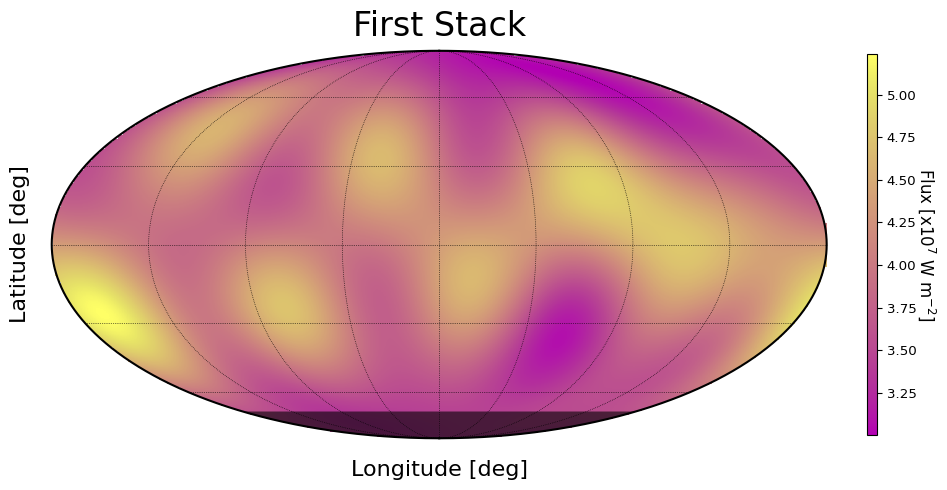

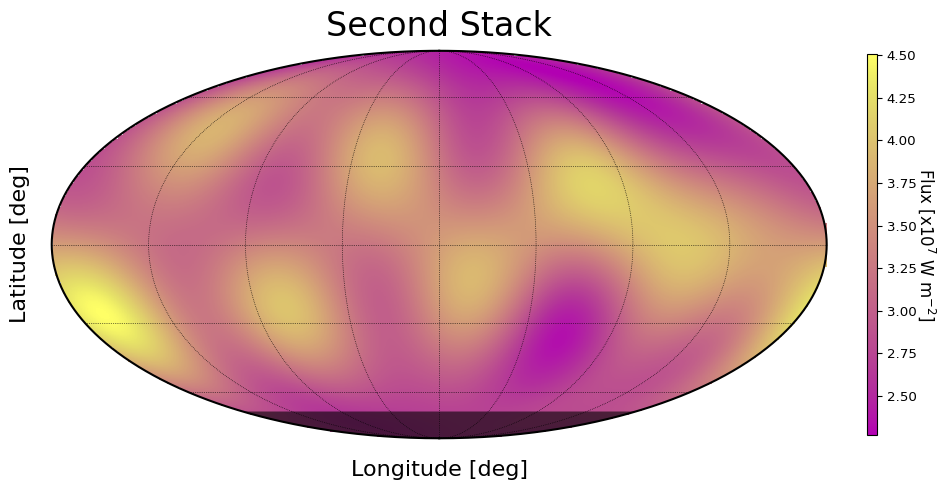

In [24]:
# NEED TO ADJUST FOR LIMB
realistic_star.map.amp /= ratio

create_emaps.emap_plot(stacked_star, proj='moll', cmap = cm.buda, units=units,title="First Stack")

realistic_star.map.amp *= ratio

realistic_star.map.amp /= ratio

create_emaps.emap_plot(realistic_star, proj='moll', cmap = cm.buda, units=units,title="Second Stack")

realistic_star.map.amp *= ratio

## Stacking a lot of Null Space Maps

So now we can add 5 different null space maps to see the resulting RV curve.  This is also a good test to see if null space patterns can cancel or amplify signals.  Lets start by looking at the RV curves:

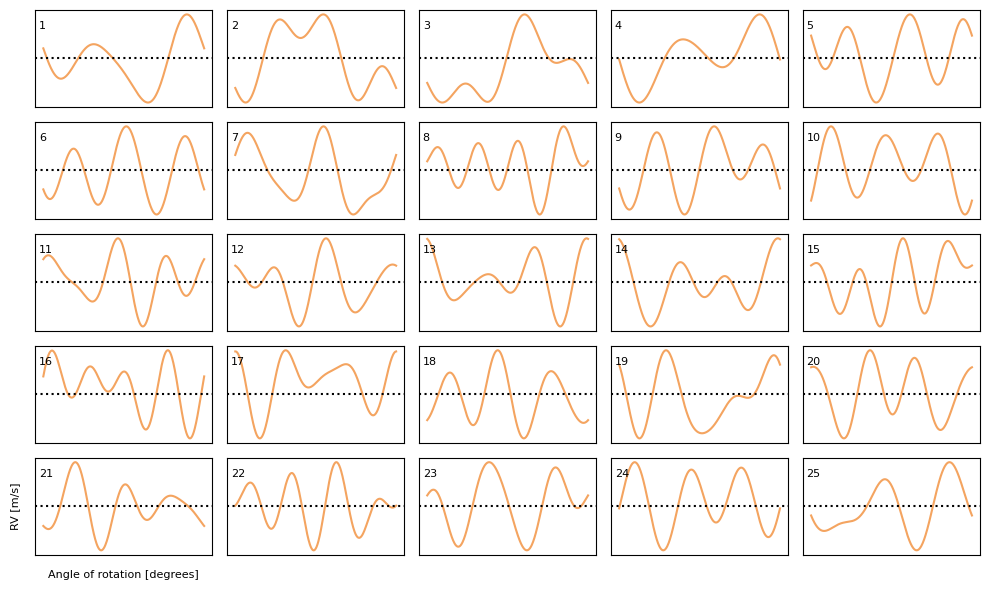

In [25]:
norm_eigeny = np.loadtxt("../eridani-outputs/quad-limb-70i-units/stored-norm-null-eigens/norm-null-eigeny.txt")

star = utils.initstar(fit, lmax, udeg=udeg, include_rv=True)

ncurves, ny = norm_eigeny.shape

ncols = int(np.sqrt(ncurves) // 1)
nrows = int(ncurves // ncols + (ncurves % ncols != 0))

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, squeeze=False,
                            sharex=True, sharey=False, figsize=(10, 6))

for j in range(ncurves):
    star.map[:,:] = norm_eigeny[j]

    star.map[0,0] = 1 + norm_eigeny[j][0]

    xloc = j %  ncols
    yloc = j // ncols
    ax = axes[yloc, xloc]

    j_rv = star.map.rv(theta=theta).eval()
    
    ax.plot(theta, j_rv,color="sandybrown")


    ax.text(x=.02, y=.8, s=f"{j+1}", fontsize=16*.5, transform=ax.transAxes)

    if xloc == 0 and yloc == nrows - 1:
            ax.set_xlabel("Angle of rotation [degrees]",fontsize=16*.5)
            
            ax.set_ylabel(f"RV [m/s]",fontsize=16*.5)

    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.tick_params(left=False, bottom=False)


    middle = (np.max(j_rv) + np.min(j_rv)) / 2
    ax.axhline(y=middle,color="k",linestyle=":")


fig.tight_layout()
plt.show()

Now these maps are not scaled but the shape will be constant across maps.  

So, maybe we pick out the following ones with some cool structure: (index of each is -1 label): 4, 11, 17, 20, & 25

In [26]:
stacked_eigeny = norm_eigeny[4-3] + norm_eigeny[11-1] + norm_eigeny[17-1] + norm_eigeny[20-1] + norm_eigeny[25-1]

And like before, we can scale it to be realistic (this may take a bit to run, we can speed it up by increasing interval)

In [27]:
realistic_star, inv_realistic_star, uni_star_limb, uni_star, ratio_no_limb =\
                                    create_real_null.set_up_stars(fit, stacked_eigeny, uni_comp=1)


realistic_star, inv_realistic_star, uni_star_limb, adj_uni_comp, ratio_below, ratio_above, uni_value = \
                create_real_null.set_up_real_map(realistic_star, inv_realistic_star, uni_star_limb, ratio_no_limb,interval=.4)

create_real_null.scale_real_map(realistic_star, uni_star_limb, 
                        scale_value=scaler, uni_comp=adj_uni_comp, 
                        ratio_no_limb=ratio_no_limb,scaler="lc")


print(f"Range fo flux is now {ratio_below} to {ratio_above}")

Range fo flux is now 0.6711512375708069 to 1.3499090140678125


Let's look at this new RV curve compared to the old ones using the realistic outputs from earlier

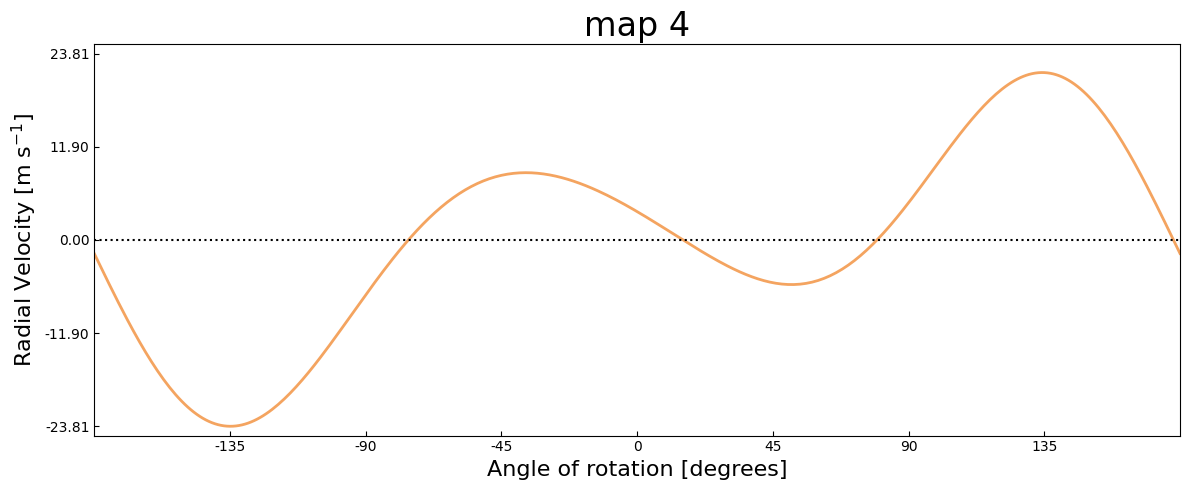

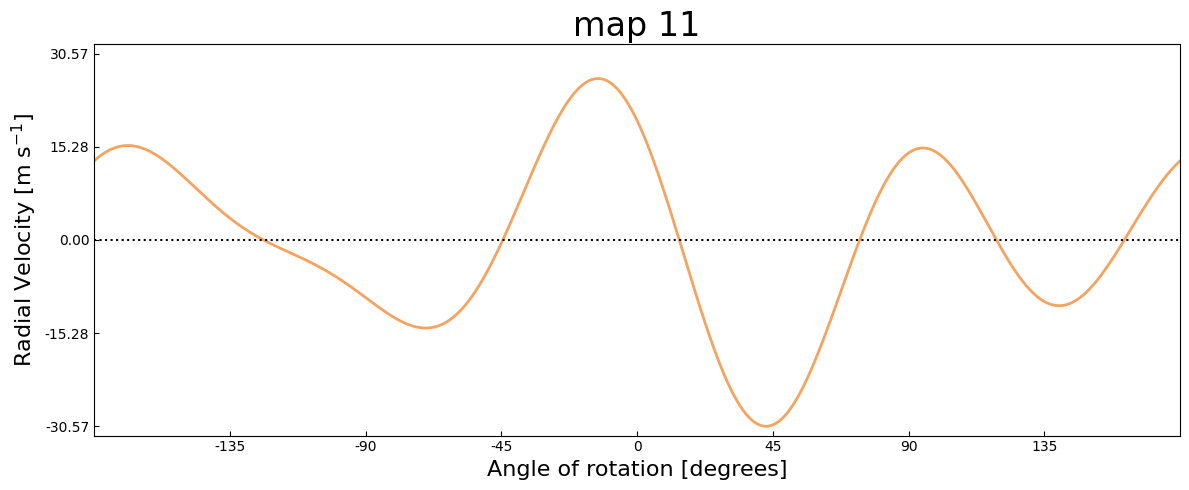

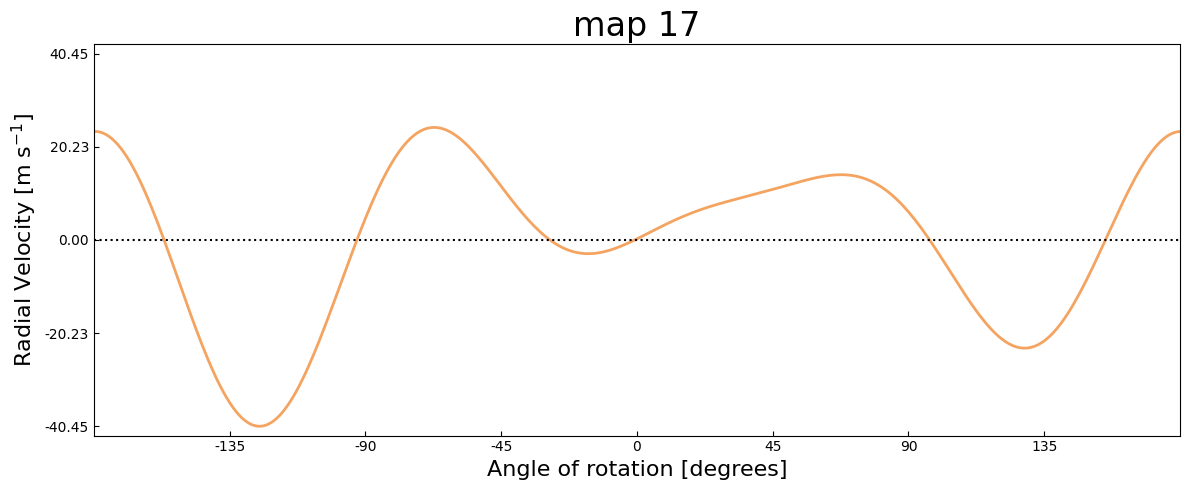

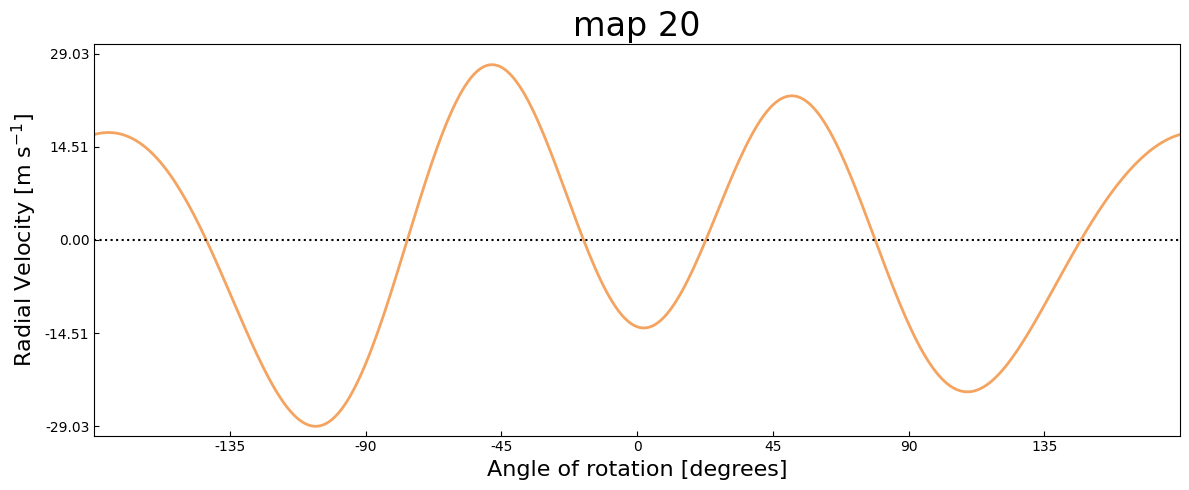

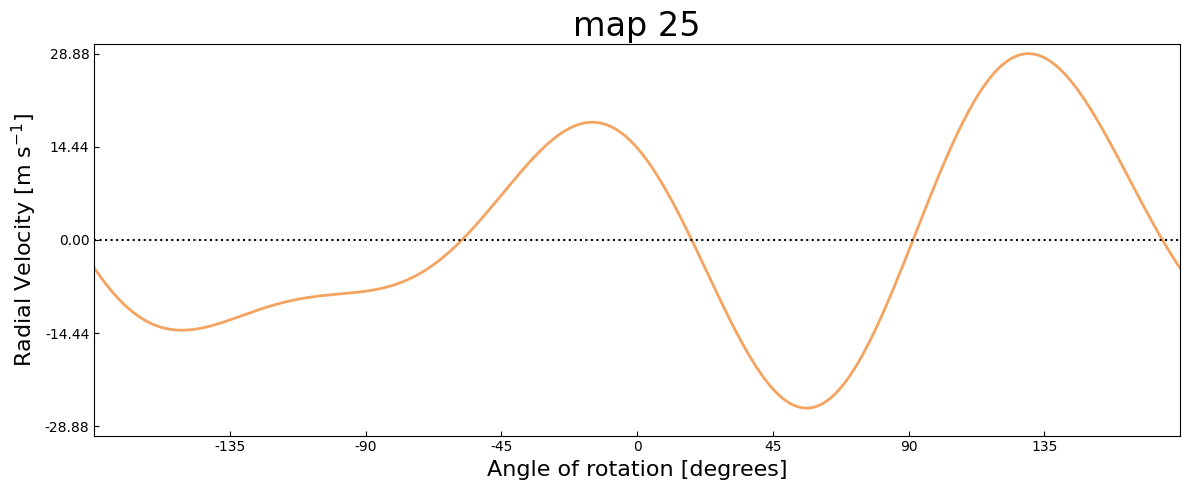

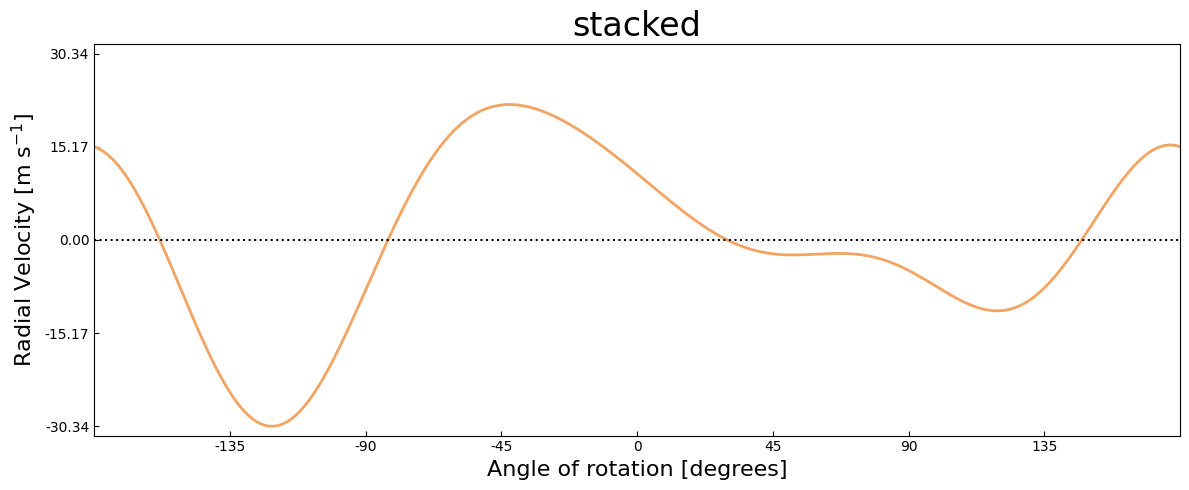

In [28]:
star = utils.initstar(fit, lmax, udeg=udeg, include_rv=True)

for i in [3,10,16,19,24,50]:

    if i == 50:
        star.map[:,:] = realistic_star.map[:,:].copy()
        create_rv.flux_rv_line(star,theta = theta, rv_only=True,title="stacked")
    else:
        star.map[:,:] = scaled_eigeny[i]
        create_rv.flux_rv_line(star,theta=theta,rv_only=True,title=f"map {i+1}")


    

It is a little hard to make out, but if you scroll through it makes sense why the left side would add together while the right would be dampened by this map combination.  Still, the RV remains in order of 10 m/s amplitude.

Here is the animated version of the new map:

In [29]:
create_rv.map_animations(realistic_star, html5_video=True, dpi=100, interval=50, units=units)

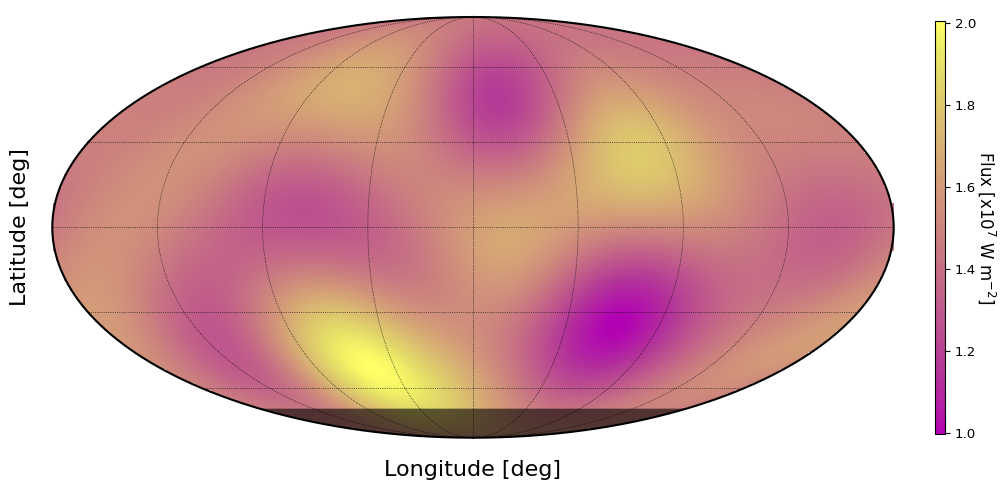

In [30]:
# NEED TO ADJUST FOR LIMB
realistic_star.map.amp /= ratio

create_emaps.emap_plot(realistic_star, proj='moll', cmap = cm.buda, units=units)

realistic_star.map.amp *= ratio